# CardioGuard - Cardiovascular Disease Predictor

## Problem Statement

Cardiovascular diseases remain one of the leading causes of death globally accounting for nearly 18 million fatalities annually. Early detection plays a vital role in enabling timely intervention and significantly reducing mortality rates. However, traditional diagnostic approaches rely heavily on lengthy and costly clinical evaluations, creating barriers to accessible and rapid health assessments.

## Objective

To develop a cardiovascular disease prediction model using different machine learning models.

## Data Description



**Features**
1. **id** - Unique identifier for each patient
2. **age** - Age of patient in days
3. **gender** - Gender of the patient. Categorical variable(1: Female, 2: Male)
4. **height** - Height of the patient in centimeters
5. **weight** - Weight of the patient in kilograms
6. **ap_hi** - Systolic blood pressure
7. **ap_lo** - Diastolic blood pressure
8. **cholesterol** - Cholesterol levels. Categorical variable(1: Normal, 2: Above Normal, 3: Well Above Normal).
9. **gluc** - Glucose levels. Categorical variable (1: Normal, 2: Above Normal, 3: Well Above Normal).
10. **smoke** - Smoking status. Binary variable (0: Non-smoker, 1: Smoker).
11. **alco** - Alcohol intake. Binary variable (0: Does not consume alcohol, 1:Consumes Alcohol)
12. **active** - Physical activity. Binary variable (0: Not physically active, 1: Physically active)
13. **cardio** - Presence or absence of cardiovascular disease. Binary variable (0: Absence, 1: Presence).***Target variable.***
14. **age_years** - Age of the patient in years(derived from age)
15. **bmi** - Body Mass Index, derived from weight and height.
16. **bp_category** - Blood pressure category based on ap_hi and ap_lo. Categories include "Normal", "Elevated", "Hypertension Stage 1", "Hypertension Stage 2", and "Hypertensive Crisis".
17. **bp_category_encoded**: Encoded form of bp_category for machine learning purposes.

## Data Collection

In [1]:
# Importing the pandas module
import pandas as pd
from sklearn import ensemble

In [2]:
# Loading the dataset
dataset=pd.read_csv('../dataset/cardio_data_processed.csv')

In [3]:
# Viewing the first 10 rows of the dataset
dataset.head(10)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category,bp_category_encoded
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50,21.967120,Hypertension Stage 1,Hypertension Stage 1
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55,34.927679,Hypertension Stage 2,Hypertension Stage 2
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51,23.507805,Hypertension Stage 1,Hypertension Stage 1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48,28.710479,Hypertension Stage 2,Hypertension Stage 2
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47,23.011177,Normal,Normal
5,8,21914,1,151,67.0,120,80,2,2,0,0,0,0,60,29.384676,Hypertension Stage 1,Hypertension Stage 1
6,9,22113,1,157,93.0,130,80,3,1,0,0,1,0,60,37.729725,Hypertension Stage 1,Hypertension Stage 1
7,12,22584,2,178,95.0,130,90,3,3,0,0,1,1,61,29.983588,Hypertension Stage 1,Hypertension Stage 1
8,13,17668,1,158,71.0,110,70,1,1,0,0,1,0,48,28.440955,Normal,Normal
9,14,19834,1,164,68.0,110,60,1,1,0,0,0,0,54,25.282570,Normal,Normal


In [4]:
# Displaying information about the dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 68205 entries, 0 to 68204
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   68205 non-null  int64  
 1   age                  68205 non-null  int64  
 2   gender               68205 non-null  int64  
 3   height               68205 non-null  int64  
 4   weight               68205 non-null  float64
 5   ap_hi                68205 non-null  int64  
 6   ap_lo                68205 non-null  int64  
 7   cholesterol          68205 non-null  int64  
 8   gluc                 68205 non-null  int64  
 9   smoke                68205 non-null  int64  
 10  alco                 68205 non-null  int64  
 11  active               68205 non-null  int64  
 12  cardio               68205 non-null  int64  
 13  age_years            68205 non-null  int64  
 14  bmi                  68205 non-null  float64
 15  bp_category          68205 non-null  str    
 1

## Data Preprocessing

In [5]:
# Creating a copy of the dataset
data_copy=dataset.copy()

### Checking for duplicate rows

In [6]:
data_copy.duplicated().sum()

np.int64(0)

***No duplicate rows have been identified in the dataset.***

### Checking for missing values

In [7]:
data_copy.isna().sum()

id                     0
age                    0
gender                 0
height                 0
weight                 0
ap_hi                  0
ap_lo                  0
cholesterol            0
gluc                   0
smoke                  0
alco                   0
active                 0
cardio                 0
age_years              0
bmi                    0
bp_category            0
bp_category_encoded    0
dtype: int64

***No missing values have been identified in the dataset.***

### Checking for outliers

In [8]:
# Fetching numeric columns after removing id column, categorical columns and other binary columns
numeric_cols=data_copy.drop(columns=['id','gender','cholesterol','gluc','smoke','alco','active','cardio','bp_category','bp_category_encoded']).columns.tolist()

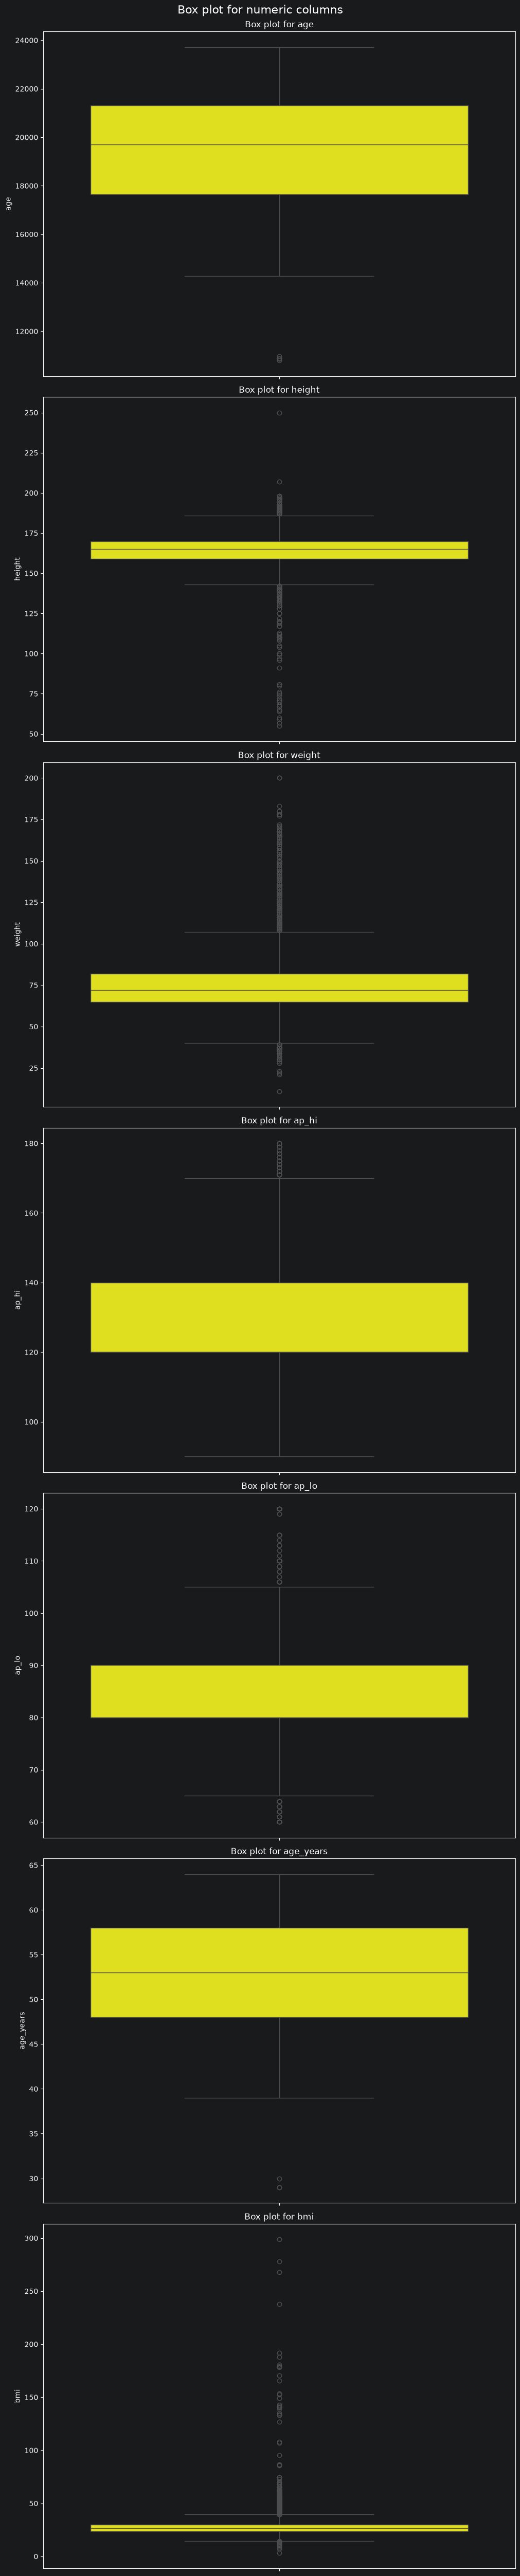

In [9]:
# Plotting box blot for all numeric columns except id
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax=plt.subplots(7,figsize=(10,50), constrained_layout=True)
for i in range(7):
    sns.boxplot(
        data=data_copy,
        y=numeric_cols[i],
        color='yellow',
        ax=ax[i]
    )
    ax[i].set_title(f"Box plot for {numeric_cols[i]}")
fig.suptitle("Box plot for numeric columns", fontsize=16)
plt.show()

In [10]:
# Displaying the outlier count for each column and removing the outliers
row_removal_count=0
for i in numeric_cols:
    Q1=data_copy[i].quantile(0.25)
    Q3=data_copy[i].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    outlier_mask=(data_copy[i]>upper_bound) | (data_copy[i]<lower_bound)
    outlier_count=outlier_mask.sum()
    print(f"Outlier count for {i} column : {outlier_count}")
    if outlier_count>0:
        data_copy=data_copy[
            (data_copy[i]>=lower_bound)
            &
            (data_copy[i]<=upper_bound)
        ]
        row_removal_count+=outlier_count
print(f"{row_removal_count} rows have been removed from the dataset.")

Outlier count for age column : 4
Outlier count for height column : 502
Outlier count for weight column : 1652
Outlier count for ap_hi column : 581
Outlier count for ap_lo column : 2964
Outlier count for age_years column : 0
Outlier count for bmi column : 1173
6876 rows have been removed from the dataset.


### Checking for skewness

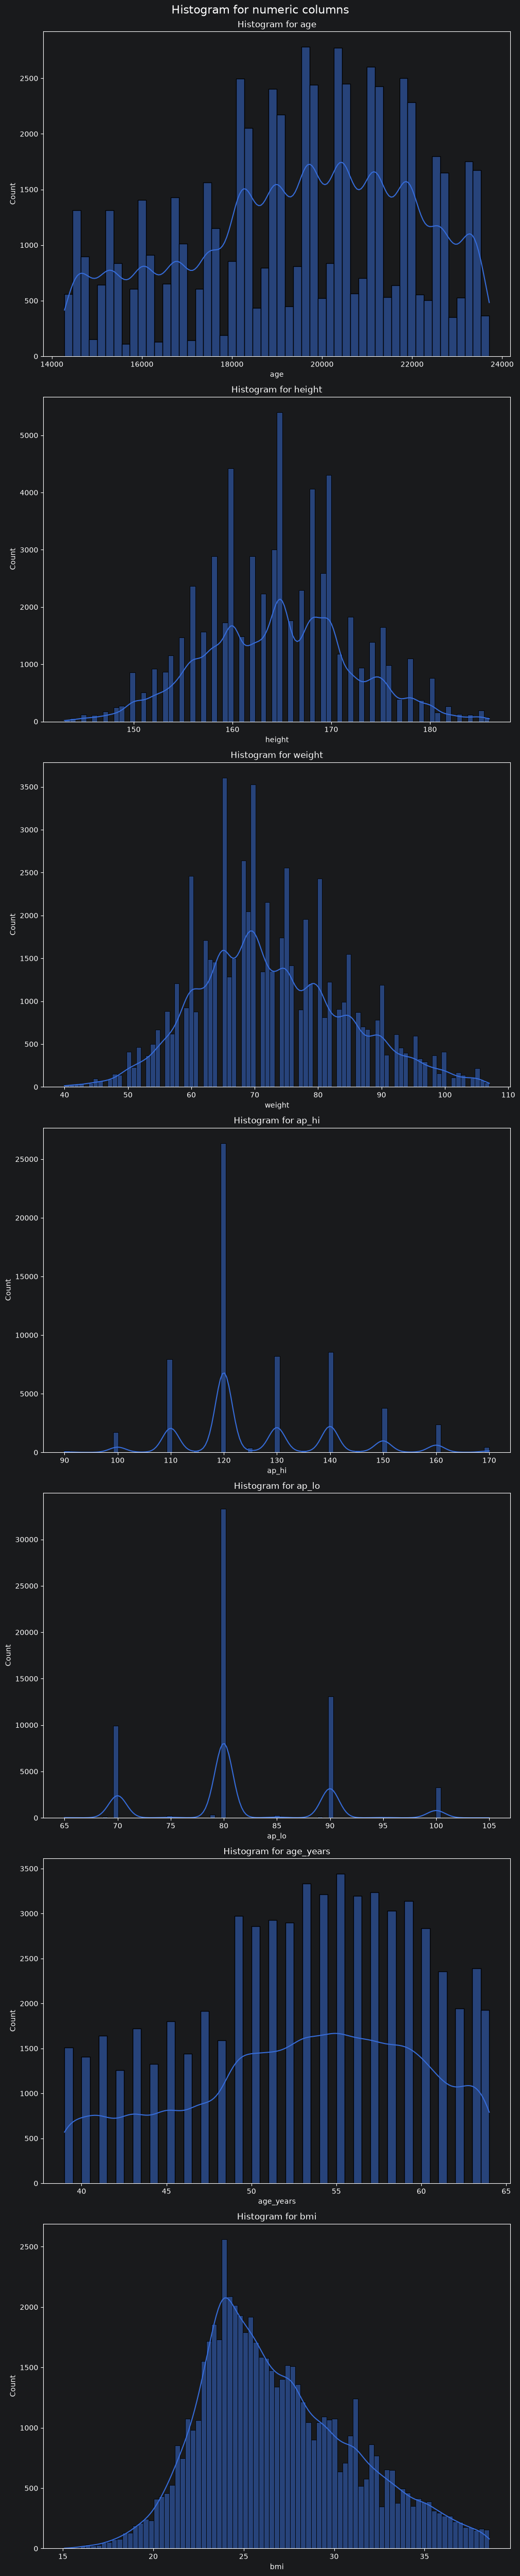

In [11]:
fig, ax=plt.subplots(7,figsize=(10,50), constrained_layout=True)
for i in range(7):
    sns.histplot(
        data=data_copy,
        x=numeric_cols[i],
        kde=True,
        ax=ax[i]
    )
    ax[i].set_title(f"Histogram for {numeric_cols[i]}")
fig.suptitle("Histogram for numeric columns", fontsize=16)
plt.show()

In [12]:
# Displaying skewness for each numerical column
for i in numeric_cols:
    skew_value=data_copy[i].skew()
    print(f"Skewness value for {i} column :{skew_value}")

Skewness value for age column :-0.3103748148092879
Skewness value for height column :0.061879344277052495
Skewness value for weight column :0.35063737084283303
Skewness value for ap_hi column :0.738009087706476
Skewness value for ap_lo column :0.454052144885667
Skewness value for age_years column :-0.30912222542960416
Skewness value for bmi column :0.5185359159597256


***The columns age, height, weight, ap_lo, age_years and bmi are fairly symmetrical. The column ap_hi is positively skewed but since it is a medical parameter, transformation is not applied to this column.***

### Checking for irrelevant values

Systolic pressure should be higher than diastolic pressure.

In [13]:
# Extracting rows where the systolic pressure is lower than the diastolic pressure
irrelevant_pressure_rows=data_copy[data_copy['ap_hi']<=data_copy['ap_lo']]
irrelevant_pressure_rows

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category,bp_category_encoded
12466,18238,15787,2,178,105.0,100,100,1,1,0,0,0,1,43,33.139755,Hypertension Stage 2,Hypertension Stage 2
22303,32702,20467,2,178,84.0,95,100,1,1,0,1,0,1,56,26.511804,Hypertension Stage 2,Hypertension Stage 2
45316,66423,15215,2,178,92.0,90,100,1,1,1,0,1,0,41,29.036738,Hypertension Stage 2,Hypertension Stage 2


In [14]:
# Removing these rows
data_copy=data_copy[data_copy['ap_hi']>data_copy['ap_lo']]

## Exploratory Data Analysis

In [15]:
# Displaying statistical information about the dataset
data_copy[numeric_cols].describe()

,age,height,weight,ap_hi,ap_lo,age_years,bmi
count,61326.000000,61326.000000,61326.000000,61326.000000,61326.000000,61326.000000,61326.000000
mean,19483.128836,164.568829,72.701733,126.264260,81.626211,52.879725,26.864775
std,2459.315009,7.478592,11.843475,14.226551,7.644597,6.744967,4.200081
min,14282.000000,143.000000,40.000000,90.000000,65.000000,39.000000,15.094795
25%,17700.000000,159.000000,65.000000,120.000000,80.000000,48.000000,23.833005
50%,19712.000000,165.000000,71.000000,120.000000,80.000000,54.000000,26.128611
75%,21332.000000,170.000000,80.000000,140.000000,90.000000,58.000000,29.608376
max,23713.000000,186.000000,107.000000,170.000000,105.000000,64.000000,38.580247


### Gender Distribution in Positive Cardiovascular Disease Patients

A pie chart showing the proportion of male and female patients among confirmed cardiovascular disease patients.

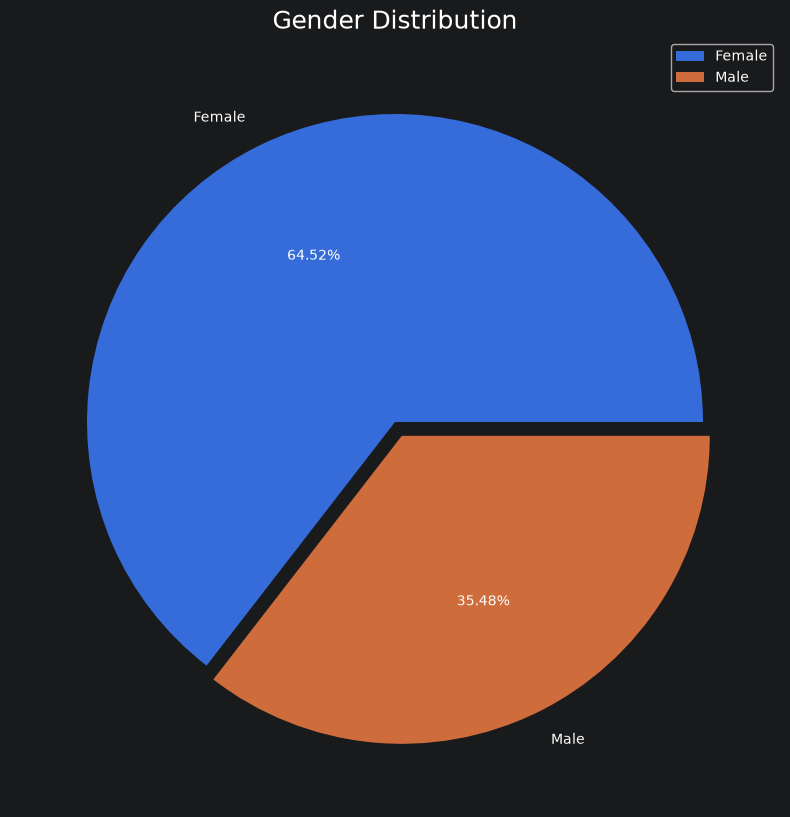

In [16]:
data_copy_positive=data_copy[data_copy['cardio']==1]
gender_distribution=data_copy_positive['gender'].value_counts()
fig, ax=plt.subplots(figsize=(10,10))
ax.pie(
    gender_distribution.values,
    labels=['Female','Male'],
    autopct="%1.2f%%",
    explode=[0, 0.05]
)
ax.set_title("Gender Distribution", fontsize=18)
ax.legend()
plt.show()


***Among positive cardiovascular cases the number of female patients exceeds male patients by 29.04%.***

### Age Distribution in Positive Cardiovascular Disease Patients

A bar plot showing the age distribution among confirmed cardiovascular disease patients.

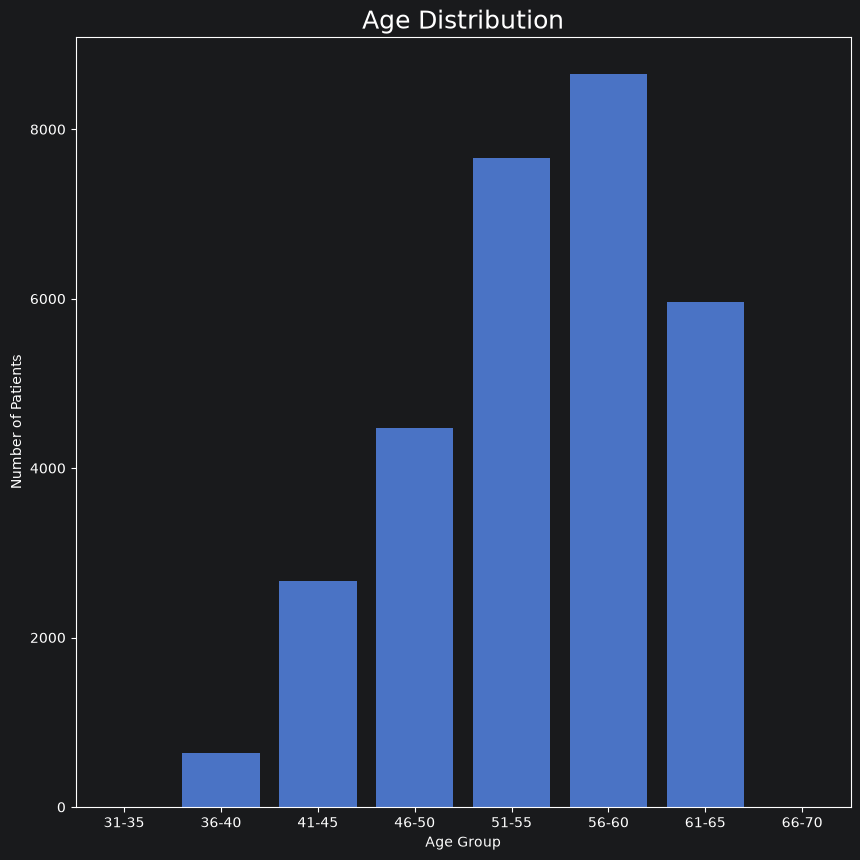

In [17]:
age_distribution=pd.DataFrame(
    {
        'Age group':['31-35', '36-40', '41-45', '46-50', '51-55', '56-60', '61-65', '66-70'],
        'Number of patients':[
            data_copy_positive[(data_copy_positive['age_years']>=31) & (data_copy_positive['age_years']<=35)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=36) & (data_copy_positive['age_years']<=40)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=41) & (data_copy_positive['age_years']<=45)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=46) & (data_copy_positive['age_years']<=50)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=51) & (data_copy_positive['age_years']<=55)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=56) & (data_copy_positive['age_years']<=60)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=61) & (data_copy_positive['age_years']<=65)]['id'].count(),
            data_copy_positive[(data_copy_positive['age_years']>=66) & (data_copy_positive['age_years']<=70)]['id'].count(),
        ]
    }
)
fig, ax=plt.subplots(figsize=(10,10))
sns.barplot(
    x=age_distribution['Age group'],
    y=age_distribution['Number of patients']
)
ax.set_title("Age Distribution", fontsize=18)
ax.set_xlabel("Age Group")
ax.set_ylabel("Number of Patients")
plt.show()

***Among positive cardiovascular cases, the most prominent age group is 56-60.***

### Cardiovascular Disease Probability by Cholesterol Level

This bar chart shows the probability of developing cardiovascular disease based on cholesterol levels.

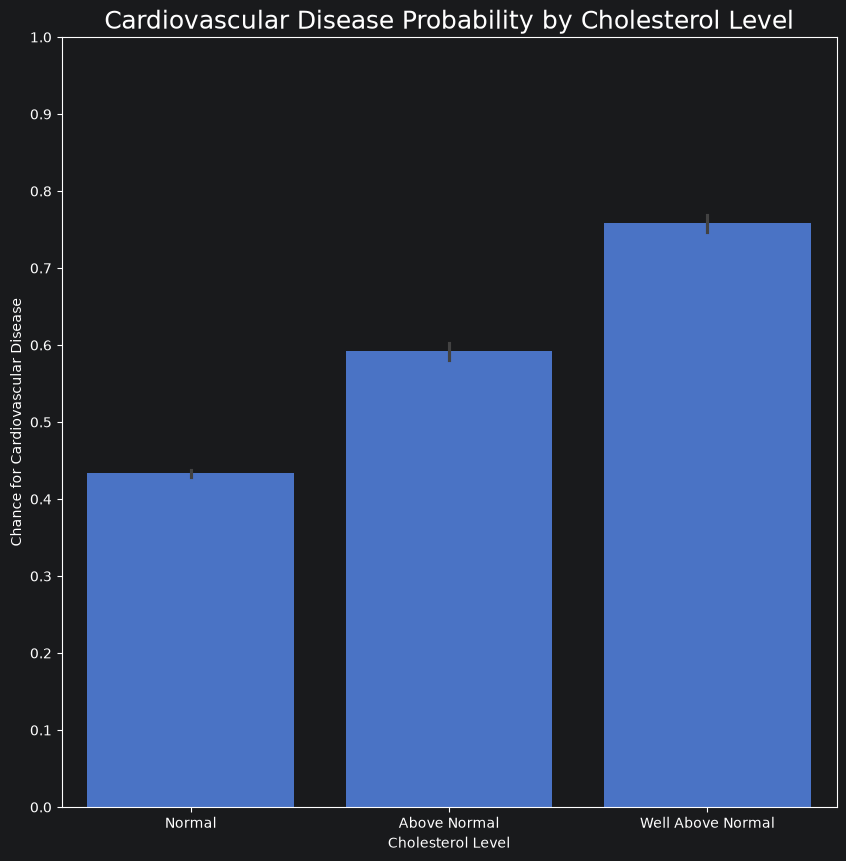

In [18]:
cholesterol_level_distribution=data_copy[['cholesterol','cardio']]
cholesterol_level_distribution['cholesterol']=cholesterol_level_distribution['cholesterol'].map({1:'Normal', 2:'Above Normal', 3:'Well Above Normal'})
fig, ax=plt.subplots(figsize=(10,10))
sns.barplot(
    data=cholesterol_level_distribution,
    x='cholesterol',
    y='cardio',
    order=[
        'Normal',
        'Above Normal',
        'Well Above Normal'
    ]
)
ax.set_title("Cardiovascular Disease Probability by Cholesterol Level", fontsize=18)
ax.set_xlabel('Cholesterol Level')
ax.set_ylabel('Chance for Cardiovascular Disease')
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0])
plt.show()

***People with cholesterol levels well above normal have a higher probability of developing cardiovascular disease.***

### Cardiovascular Disease Probability by Glucose Level

This bar chart shows the probability of developing cardiovascular diseases based on glucose levels.

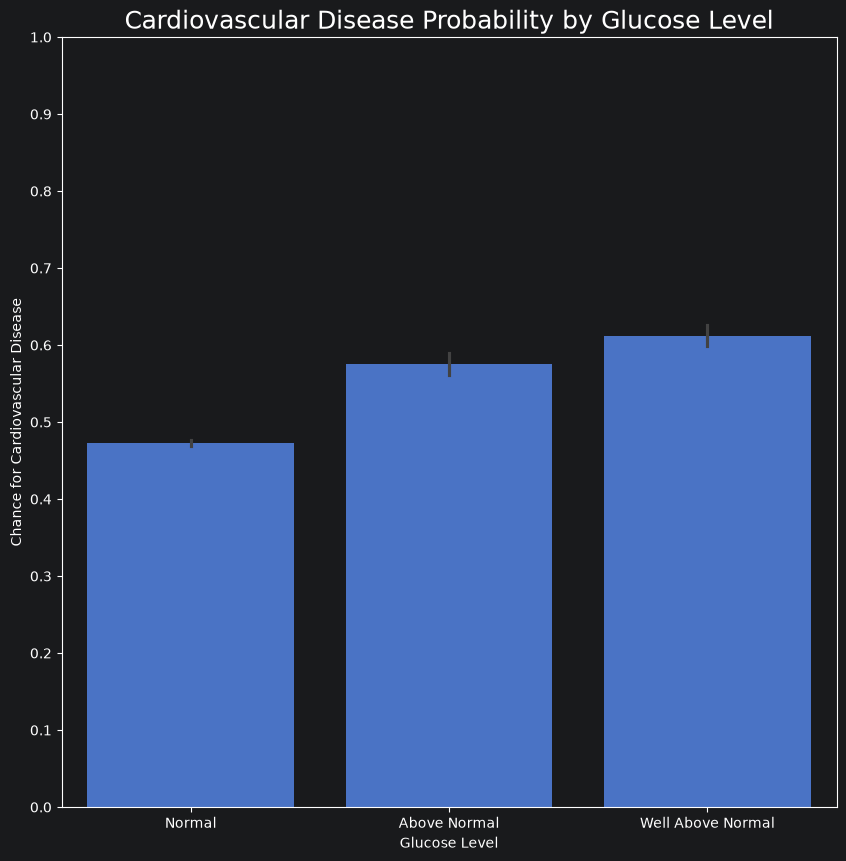

In [19]:
glucose_level_distribution=data_copy[['gluc','cardio']]
glucose_level_distribution['gluc']=glucose_level_distribution['gluc'].map({1:'Normal', 2:'Above Normal', 3:'Well Above Normal'})
fig, ax=plt.subplots(figsize=(10,10))
sns.barplot(
    data=glucose_level_distribution,
    x='gluc',
    y='cardio'
)
ax.set_title("Cardiovascular Disease Probability by Glucose Level",fontsize=18)
ax.set_xlabel("Glucose Level")
ax.set_ylabel("Chance for Cardiovascular Disease")
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])
plt.show()

***People with glucose levels well above normal have a higher probability of developing cardiovascular diseases.***

### Correlation

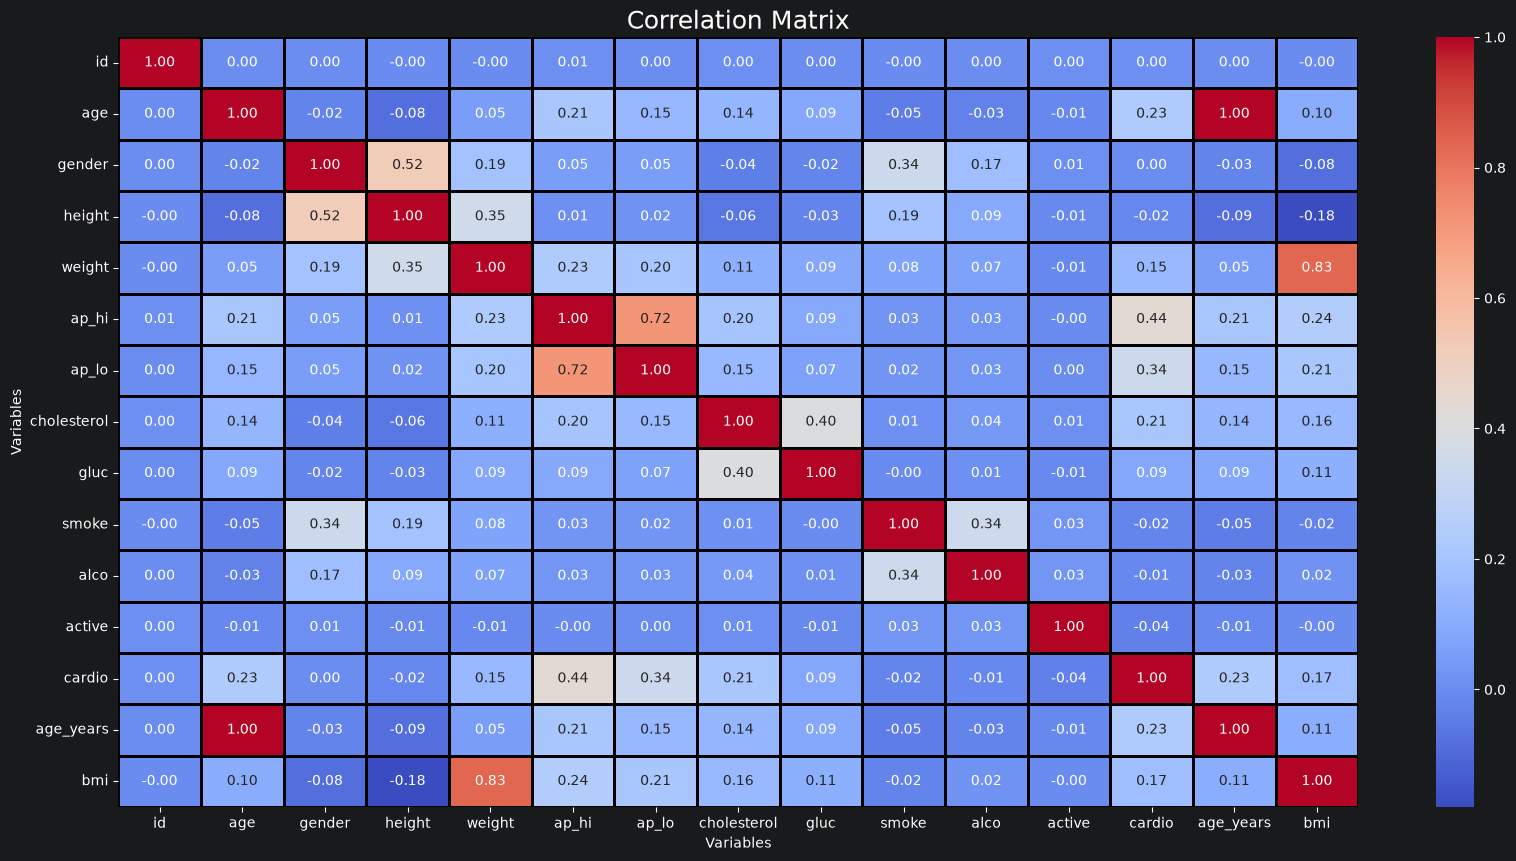

In [20]:
correlation=data_copy.corr(numeric_only=True, method='spearman')
fig, ax=plt.subplots(figsize=(20,10))
sns.heatmap(
    data=correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=1,
    linecolor='black'
)
ax.set_title("Correlation Matrix", fontsize=18)
ax.set_xlabel("Variables")
ax.set_ylabel("Variables")
plt.show()

**Conclusions**
1. Age has positive correlations with cardio indicating higher risk of cardiovascular disease as age increases.
2. Gender has positive correlation with height indicating height differences across genders.
3. Weight has a strong correlation with bmi since bmi is calculated from weight.
4. There is a strong correlation between systolic pressure(ap_hi) and diastolic pressure(ap_lo).
5. Systolic pressure (ap_hi) and diastolic pressure(ap_lo) have positive correlations with cardio indicating their role in cardiovascular diseases.
6. Cholesterol and glucose levels(gluc) have positive correlations with cardio indicating that a rise in both will result in an increase in chance of cardiovascular disease.
7. There is a strong correlation between age and age_years since both are the same.

## Feature Engineering

In [21]:
data_copy.info()

<class 'pandas.DataFrame'>
Index: 61326 entries, 0 to 68204
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   61326 non-null  int64  
 1   age                  61326 non-null  int64  
 2   gender               61326 non-null  int64  
 3   height               61326 non-null  int64  
 4   weight               61326 non-null  float64
 5   ap_hi                61326 non-null  int64  
 6   ap_lo                61326 non-null  int64  
 7   cholesterol          61326 non-null  int64  
 8   gluc                 61326 non-null  int64  
 9   smoke                61326 non-null  int64  
 10  alco                 61326 non-null  int64  
 11  active               61326 non-null  int64  
 12  cardio               61326 non-null  int64  
 13  age_years            61326 non-null  int64  
 14  bmi                  61326 non-null  float64
 15  bp_category          61326 non-null  str    
 16  bp

Column id is irrelevant so this column is removed.

Columns age and age_years are same in context so only considering the age_years column.

Even though bmi is calculated using weight and height, two persons having the same bmi may not have the same weight and height so bmi column is required.

Columns bp_category and bp_category_encoded are same so bp_category_encoded column is removed.

In [22]:
from sklearn.preprocessing import OrdinalEncoder
bp_categories=['Normal','Elevated','Hypertension Stage 1','Hypertension Stage 2','Hypertensive Crisis']
ordinal_encoder=OrdinalEncoder(categories=[bp_categories])
data_copy['bp_category']=ordinal_encoder.fit_transform(data_copy[['bp_category']])

In [23]:
data_copy=data_copy.drop(columns=['id','age','bp_category_encoded'])

In [24]:
data_copy.head(10)

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category
0,2,168,62.0,110,80,1,1,0,0,1,0,50,21.967120,2.0
1,1,156,85.0,140,90,3,1,0,0,1,1,55,34.927679,3.0
2,1,165,64.0,130,70,3,1,0,0,0,1,51,23.507805,2.0
3,2,169,82.0,150,100,1,1,0,0,1,1,48,28.710479,3.0
5,1,151,67.0,120,80,2,2,0,0,0,0,60,29.384676,2.0
6,1,157,93.0,130,80,3,1,0,0,1,0,60,37.729725,2.0
7,2,178,95.0,130,90,3,3,0,0,1,1,61,29.983588,2.0
8,1,158,71.0,110,70,1,1,0,0,1,0,48,28.440955,0.0
10,1,169,80.0,120,80,1,1,0,0,1,0,61,28.010224,2.0
11,2,173,60.0,120,80,1,1,0,0,1,0,51,20.047446,2.0


## Splitting Data into Training and Testing Sets

In [25]:
data_copy['cardio'].value_counts()

cardio
0    31266
1    30060
Name: count, dtype: int64

***The dataset is a balanced dataset.***

In [26]:
X=data_copy.drop(columns=['cardio'])
y=data_copy['cardio']

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.2,random_state=42, stratify=y)

## Feature Scaling

In [28]:
# Using StandardScaler for scaling the dataset
from sklearn.preprocessing import StandardScaler
standard_scaler=StandardScaler()
X_train_scaled=standard_scaler.fit_transform(X_train)
X_test_scaled=standard_scaler.transform(X_test)

## Model Building

### Logistic Regression

In [29]:
from sklearn.linear_model import LogisticRegression
logistic_regression=LogisticRegression()
logistic_regression.fit(X_train_scaled, y_train)
y_pred_logistic_regression=logistic_regression.predict(X_test_scaled)

In [30]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, roc_curve, auc, classification_report

accuracy_logistic_regression=accuracy_score(y_test, y_pred_logistic_regression)
recall_logistic_regression=recall_score(y_test,y_pred_logistic_regression)
precision_logistic_regression=precision_score(y_test, y_pred_logistic_regression)
f1_score_logistic_regression=f1_score(y_test, y_pred_logistic_regression)
confusion_matrix_logistic_regression=confusion_matrix(y_test, y_pred_logistic_regression)
print(f"Accuracy: {accuracy_logistic_regression}")
print(f"Recall: {recall_logistic_regression}")
print(f"Precision: {precision_logistic_regression}")
print(f"F1 Score: {f1_score_logistic_regression}")
print("Confusion Matrix")
print(confusion_matrix_logistic_regression)
print("Classification Report")
print(classification_report(y_test, y_pred_logistic_regression))

Accuracy: 0.7211804989401598
Recall: 0.6492015968063872
Precision: 0.7485615650172612
F1 Score: 0.6953500801710315
Confusion Matrix
[[4943 1311]
 [2109 3903]]
Classification Report
              precision    recall  f1-score   support

           0       0.70      0.79      0.74      6254
           1       0.75      0.65      0.70      6012

    accuracy                           0.72     12266
   macro avg       0.72      0.72      0.72     12266
weighted avg       0.72      0.72      0.72     12266



### Decision Tree Classifier

In [31]:
from sklearn.tree import DecisionTreeClassifier
decision_tree=DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train_scaled, y_train)
y_pred_decision_tree=decision_tree.predict(X_test_scaled)

In [32]:
accuracy_decision_tree=accuracy_score(y_test, y_pred_decision_tree)
recall_decision_tree=recall_score(y_test, y_pred_decision_tree)
precision_decision_tree=precision_score(y_test, y_pred_decision_tree)
f1_score_decision_tree=f1_score(y_test, y_pred_decision_tree)
confusion_matrix_decision_tree=confusion_matrix(y_test, y_pred_decision_tree)
print(f"Accuracy: {accuracy_decision_tree}")
print(f"Recall: {recall_decision_tree}")
print(f"Precision: {precision_decision_tree}")
print(f"F1 Score: {f1_score_decision_tree}")
print("Confusion Matrix")
print(confusion_matrix_decision_tree)
print("Classification Report")
print(classification_report(y_test, y_pred_decision_tree))

Accuracy: 0.6271808250448394
Recall: 0.6077844311377245
Precision: 0.6225932867609474
F1 Score: 0.6150997390792021
Confusion Matrix
[[4039 2215]
 [2358 3654]]
Classification Report
              precision    recall  f1-score   support

           0       0.63      0.65      0.64      6254
           1       0.62      0.61      0.62      6012

    accuracy                           0.63     12266
   macro avg       0.63      0.63      0.63     12266
weighted avg       0.63      0.63      0.63     12266



### Random Forest Classifier

In [33]:
from sklearn.ensemble import RandomForestClassifier
random_forest=RandomForestClassifier(random_state=42)
random_forest.fit(X_train_scaled, y_train)
y_pred_random_forest=random_forest.predict(X_test_scaled)

In [34]:
accuracy_random_forest=accuracy_score(y_test, y_pred_random_forest)
recall_random_forest=recall_score(y_test, y_pred_random_forest)
precision_random_forest=precision_score(y_test, y_pred_random_forest)
f1_score_random_forest=f1_score(y_test, y_pred_random_forest)
confusion_matrix_random_forest=confusion_matrix(y_test, y_pred_random_forest)
print(f"Accuracy: {accuracy_random_forest}")
print(f"Recall: {recall_random_forest}")
print(f"Precision: {precision_random_forest}")
print(f"F1 Score: {f1_score_random_forest}")
print("Confusion Matrix")
print(confusion_matrix_random_forest)
print("Classification Report")
print(classification_report(y_test, y_pred_random_forest))

Accuracy: 0.6945214413826838
Recall: 0.677478376580173
Precision: 0.6925692909369154
F1 Score: 0.6849407214327756
Confusion Matrix
[[4446 1808]
 [1939 4073]]
Classification Report
              precision    recall  f1-score   support

           0       0.70      0.71      0.70      6254
           1       0.69      0.68      0.68      6012

    accuracy                           0.69     12266
   macro avg       0.69      0.69      0.69     12266
weighted avg       0.69      0.69      0.69     12266



### Gradient Boost Classifier

In [35]:
from sklearn.ensemble import GradientBoostingClassifier
gradient_boost=GradientBoostingClassifier(random_state=42)
gradient_boost.fit(X_train_scaled, y_train)
y_pred_gradient_boost=gradient_boost.predict(X_test_scaled)

In [36]:
accuracy_gradient_boost=accuracy_score(y_test, y_pred_gradient_boost)
recall_gradient_boost=recall_score(y_test, y_pred_gradient_boost)
precision_gradient_boost=precision_score(y_test, y_pred_gradient_boost)
f1_score_gradient_boost=f1_score(y_test, y_pred_gradient_boost)
confusion_matrix_gradient_boost=confusion_matrix(y_test, y_pred_gradient_boost)
print(f"Accuracy: {accuracy_gradient_boost}")
print(f"Recall: {recall_gradient_boost}")
print(f"Precision: {precision_gradient_boost}")
print(f"F1 Score: {f1_score_gradient_boost}")
print("Confusion Matrix")
print(confusion_matrix_gradient_boost)
print("Classification Report")
print(classification_report(y_test, y_pred_gradient_boost))

Accuracy: 0.7263166476438937
Recall: 0.6829673985362608
Precision: 0.7388878891488213
F1 Score: 0.7098279885901979
Confusion Matrix
[[4803 1451]
 [1906 4106]]
Classification Report
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      6254
           1       0.74      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



### AdaBoost Classifier

In [37]:
from sklearn.ensemble import AdaBoostClassifier
adaboost=AdaBoostClassifier(random_state=42)
adaboost.fit(X_train_scaled, y_train)
y_pred_adaboost=adaboost.predict(X_test_scaled)

In [38]:
accuracy_adaboost=accuracy_score(y_test, y_pred_adaboost)
recall_adaboost=recall_score(y_test, y_pred_adaboost)
precision_adaboost=precision_score(y_test, y_pred_adaboost)
f1_score_adaboost=f1_score(y_test, y_pred_adaboost)
confusion_matrix_adaboost=confusion_matrix(y_test, y_pred_adaboost)
print(f"Accuracy: {accuracy_adaboost}")
print(f"Recall: {recall_adaboost}")
print(f"Precision: {precision_adaboost}")
print(f"F1 Score: {f1_score_adaboost}")
print("Confusion Matrix")
print(confusion_matrix_adaboost)
print("Classification Report")
print(classification_report(y_test, y_pred_adaboost))

Accuracy: 0.7171041904451328
Recall: 0.6289088489687292
Precision: 0.7531872509960159
F1 Score: 0.6854604786076868
Confusion Matrix
[[5015 1239]
 [2231 3781]]
Classification Report
              precision    recall  f1-score   support

           0       0.69      0.80      0.74      6254
           1       0.75      0.63      0.69      6012

    accuracy                           0.72     12266
   macro avg       0.72      0.72      0.71     12266
weighted avg       0.72      0.72      0.71     12266



### Support Vector Classifier

In [39]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
svc=CalibratedClassifierCV(SVC(random_state=42), ensemble=False)
svc.fit(X_train_scaled, y_train)
y_pred_svc=svc.predict(X_test_scaled)

In [40]:
accuracy_svc=accuracy_score(y_test, y_pred_svc)
recall_svc=recall_score(y_test, y_pred_svc)
precision_svc=precision_score(y_test, y_pred_svc)
f1_score_svc=f1_score(y_test, y_pred_svc)
confusion_matrix_svc=confusion_matrix(y_test, y_pred_svc)
print(f"Accuracy: {accuracy_svc}")
print(f"Recall: {recall_svc}")
print(f"Precision: {precision_svc}")
print(f"F1 Score: {f1_score_svc}")
print("Confusion Matrix")
print(confusion_matrix_svc)
print("Classification Report")
print(classification_report(y_test, y_pred_svc))

Accuracy: 0.7263166476438937
Recall: 0.6676646706586826
Precision: 0.7470686767169179
F1 Score: 0.7051383399209487
Confusion Matrix
[[4895 1359]
 [1998 4014]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.78      0.74      6254
           1       0.75      0.67      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.72     12266
weighted avg       0.73      0.73      0.73     12266



### K-Nearest Neighbour

In [41]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
y_pred_knn=knn.predict(X_test_scaled)

In [42]:
accuracy_knn=accuracy_score(y_test, y_pred_knn)
recall_knn=recall_score(y_test, y_pred_knn)
precision_knn=precision_score(y_test, y_pred_knn)
f1_score_knn=f1_score(y_test, y_pred_knn)
confusion_matrix_knn=confusion_matrix(y_test, y_pred_knn)
print(f"Accuracy: {accuracy_knn}")
print(f"Recall: {recall_knn}")
print(f"Precision: {precision_knn}")
print(f"F1 Score: {f1_score_knn}")
print("Confusion Matrix")
print(confusion_matrix_knn)
print("Classification Report")
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.6906897113973586
Recall: 0.6701596806387226
Precision: 0.6898972602739726
F1 Score: 0.6798852514343571
Confusion Matrix
[[4443 1811]
 [1983 4029]]
Classification Report
              precision    recall  f1-score   support

           0       0.69      0.71      0.70      6254
           1       0.69      0.67      0.68      6012

    accuracy                           0.69     12266
   macro avg       0.69      0.69      0.69     12266
weighted avg       0.69      0.69      0.69     12266



### MLP Classifier

In [43]:
from sklearn.neural_network import MLPClassifier
mlp=MLPClassifier(random_state=42, max_iter=500)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp=mlp.predict(X_test_scaled)

In [44]:
accuracy_mlp=accuracy_score(y_test, y_pred_mlp)
recall_mlp=recall_score(y_test,y_pred_mlp)
precision_mlp=precision_score(y_test, y_pred_mlp)
f1_score_mlp=f1_score(y_test, y_pred_mlp)
confusion_matrix_mlp=confusion_matrix(y_test, y_pred_mlp)
print(f"Accuracy: {accuracy_mlp}")
print(f"Recall: {recall_mlp}")
print(f"Precision: {precision_mlp}")
print(f"F1 Score: {f1_score_mlp}")
print("Confusion Matrix")
print(confusion_matrix_mlp)
print("Classification Report")
print(classification_report(y_test, y_pred_mlp))

Accuracy: 0.7250937550953857
Recall: 0.6729873586161012
Precision: 0.7421129860601614
F1 Score: 0.7058618283321703
Confusion Matrix
[[4848 1406]
 [1966 4046]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.78      0.74      6254
           1       0.74      0.67      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.72      0.72     12266
weighted avg       0.73      0.73      0.72     12266



### Naive Bayes Classifier

In [45]:
from sklearn.naive_bayes import GaussianNB
gnb=GaussianNB()
gnb.fit(X_train_scaled, y_train)
y_pred_gnb=gnb.predict(X_test_scaled)

In [46]:
accuracy_gnb=accuracy_score(y_test, y_pred_gnb)
recall_gnb=recall_score(y_test,y_pred_gnb)
precision_gnb=precision_score(y_test, y_pred_gnb)
f1_score_gnb=f1_score(y_test, y_pred_gnb)
confusion_matrix_gnb=confusion_matrix(y_test, y_pred_gnb)
print(f"Accuracy: {accuracy_gnb}")
print(f"Recall: {recall_gnb}")
print(f"Precision: {precision_gnb}")
print(f"F1 Score: {f1_score_gnb}")
print("Confusion Matrix")
print(confusion_matrix_gnb)
print("Classification Report")
print(classification_report(y_test, y_pred_gnb))

Accuracy: 0.712864829610305
Recall: 0.6329008649367931
Precision: 0.7431640625
F1 Score: 0.6836148041681639
Confusion Matrix
[[4939 1315]
 [2207 3805]]
Classification Report
              precision    recall  f1-score   support

           0       0.69      0.79      0.74      6254
           1       0.74      0.63      0.68      6012

    accuracy                           0.71     12266
   macro avg       0.72      0.71      0.71     12266
weighted avg       0.72      0.71      0.71     12266



### XGBClassifier

In [47]:
from xgboost import XGBClassifier
xgb=XGBClassifier(random_state=42)
xgb.fit(X_train_scaled, y_train)
y_pred_xgb=xgb.predict(X_test_scaled)

In [48]:
accuracy_xgb=accuracy_score(y_test, y_pred_xgb)
recall_xgb=recall_score(y_test,y_pred_xgb)
precision_xgb=precision_score(y_test, y_pred_xgb)
f1_score_xgb=f1_score(y_test, y_pred_xgb)
confusion_matrix_xgb=confusion_matrix(y_test, y_pred_xgb)
print(f"Accuracy: {accuracy_xgb}")
print(f"Recall: {recall_xgb}")
print(f"Precision: {precision_xgb}")
print(f"F1 Score: {f1_score_xgb}")
print("Confusion Matrix")
print(confusion_matrix_xgb)
print("Classification Report")
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.7210174466003587
Recall: 0.6699933466400533
Precision: 0.7369191364800586
F1 Score: 0.7018644363129465
Confusion Matrix
[[4816 1438]
 [1984 4028]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.77      0.74      6254
           1       0.74      0.67      0.70      6012

    accuracy                           0.72     12266
   macro avg       0.72      0.72      0.72     12266
weighted avg       0.72      0.72      0.72     12266



### Extra Trees Classifier

In [49]:
from sklearn.ensemble import ExtraTreesClassifier
extra_trees_classifier=ExtraTreesClassifier(random_state=42)
extra_trees_classifier.fit(X_train_scaled, y_train)
y_pred_extra_trees_classifier=extra_trees_classifier.predict(X_test_scaled)

In [50]:
accuracy_extra_trees_classifier=accuracy_score(y_test, y_pred_extra_trees_classifier)
recall_extra_trees_classifier=recall_score(y_test,y_pred_extra_trees_classifier)
precision_extra_trees_classifier=precision_score(y_test, y_pred_extra_trees_classifier)
f1_score_extra_trees_classifier=f1_score(y_test, y_pred_extra_trees_classifier)
confusion_matrix_extra_trees_classifier=confusion_matrix(y_test, y_pred_extra_trees_classifier)
print(f"Accuracy: {accuracy_extra_trees_classifier}")
print(f"Recall: {recall_extra_trees_classifier}")
print(f"Precision: {precision_extra_trees_classifier}")
print(f"F1 Score: {f1_score_extra_trees_classifier}")
print("Confusion Matrix")
print(confusion_matrix_extra_trees_classifier)
print("Classification Report")
print(classification_report(y_test, y_pred_extra_trees_classifier))

Accuracy: 0.685308984183923
Recall: 0.6719893546240852
Precision: 0.6815114709851552
F1 Score: 0.6767169179229481
Confusion Matrix
[[4366 1888]
 [1972 4040]]
Classification Report
              precision    recall  f1-score   support

           0       0.69      0.70      0.69      6254
           1       0.68      0.67      0.68      6012

    accuracy                           0.69     12266
   macro avg       0.69      0.69      0.69     12266
weighted avg       0.69      0.69      0.69     12266



### LGBMClassifier

In [51]:
from lightgbm import LGBMClassifier
lgb=LGBMClassifier(random_state=42)
lgb.fit(X_train_scaled,y_train)
y_pred_lgb=lgb.predict(X_test_scaled)

[LightGBM] [Info] Number of positive: 24048, number of negative: 25012
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001399 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 561
[LightGBM] [Info] Number of data points in the train set: 49060, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.490175 -> initscore=-0.039304
[LightGBM] [Info] Start training from score -0.039304


In [52]:
accuracy_lgb=accuracy_score(y_test, y_pred_lgb)
recall_lgb=recall_score(y_test,y_pred_lgb)
precision_lgb=precision_score(y_test, y_pred_lgb)
f1_score_lgb=f1_score(y_test, y_pred_lgb)
confusion_matrix_lgb=confusion_matrix(y_test, y_pred_lgb)
print(f"Accuracy: {accuracy_lgb}")
print(f"Recall: {recall_lgb}")
print(f"Precision: {precision_lgb}")
print(f"F1 Score: {f1_score_lgb}")
print("Confusion Matrix")
print(confusion_matrix_lgb)
print("Classification Report")
print(classification_report(y_test, y_pred_lgb))

Accuracy: 0.729985325289418
Recall: 0.6786427145708582
Precision: 0.7472527472527473
F1 Score: 0.7112970711297071
Confusion Matrix
[[4874 1380]
 [1932 4080]]
Classification Report
              precision    recall  f1-score   support

           0       0.72      0.78      0.75      6254
           1       0.75      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



### CatBoost Classifier

In [53]:
from catboost import CatBoostClassifier
catboost=CatBoostClassifier(random_state=42)
catboost.fit(X_train_scaled, y_train)
y_pred_catboost=catboost.predict(X_test_scaled)

Learning rate set to 0.054309
0:	learn: 0.6776531	total: 150ms	remaining: 2m 29s
1:	learn: 0.6638679	total: 155ms	remaining: 1m 17s
2:	learn: 0.6517852	total: 162ms	remaining: 53.7s
3:	learn: 0.6411621	total: 167ms	remaining: 41.7s
4:	learn: 0.6316748	total: 173ms	remaining: 34.5s
5:	learn: 0.6233378	total: 179ms	remaining: 29.6s
6:	learn: 0.6158074	total: 184ms	remaining: 26.1s
7:	learn: 0.6094789	total: 190ms	remaining: 23.6s
8:	learn: 0.6038180	total: 196ms	remaining: 21.6s
9:	learn: 0.5983101	total: 201ms	remaining: 19.9s
10:	learn: 0.5932980	total: 207ms	remaining: 18.6s
11:	learn: 0.5890216	total: 214ms	remaining: 17.6s
12:	learn: 0.5851880	total: 220ms	remaining: 16.7s
13:	learn: 0.5819649	total: 226ms	remaining: 15.9s
14:	learn: 0.5786481	total: 232ms	remaining: 15.2s
15:	learn: 0.5758203	total: 237ms	remaining: 14.6s
16:	learn: 0.5733246	total: 242ms	remaining: 14s
17:	learn: 0.5709667	total: 248ms	remaining: 13.5s
18:	learn: 0.5687459	total: 253ms	remaining: 13.1s
19:	learn: 

In [54]:
accuracy_catboost=accuracy_score(y_test, y_pred_catboost)
recall_catboost=recall_score(y_test,y_pred_catboost)
precision_catboost=precision_score(y_test, y_pred_catboost)
f1_score_catboost=f1_score(y_test, y_pred_catboost)
confusion_matrix_catboost=confusion_matrix(y_test, y_pred_catboost)
print(f"Accuracy: {accuracy_catboost}")
print(f"Recall: {recall_catboost}")
print(f"Precision: {precision_catboost}")
print(f"F1 Score: {f1_score_catboost}")
print("Confusion Matrix")
print(confusion_matrix_catboost)
print("Classification Report")
print(classification_report(y_test, y_pred_catboost))

Accuracy: 0.726968857003098
Recall: 0.6781437125748503
Precision: 0.7424877071571663
F1 Score: 0.7088585586368773
Confusion Matrix
[[4840 1414]
 [1935 4077]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.77      0.74      6254
           1       0.74      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



### Voting Classifier

In [55]:
from sklearn.ensemble import VotingClassifier
vc=VotingClassifier(
    estimators=[
        ('lgb', LGBMClassifier(random_state=42)),
        ('cb', CatBoostClassifier(random_state=42)),
        ('gbc', GradientBoostingClassifier(random_state=42)),
        ('svc',CalibratedClassifierCV(SVC(random_state=42),ensemble=False)),
        ('MLP', MLPClassifier(random_state=42)),
        ('lr', LogisticRegression(random_state=42)),
        ('xgb', XGBClassifier(random_state=42))
    ],
    voting='soft',
    n_jobs=-1
)
vc.fit(X_train_scaled, y_train)
y_pred_vc=vc.predict(X_test_scaled)

In [56]:
accuracy_vc=accuracy_score(y_test, y_pred_vc)
recall_vc=recall_score(y_test,y_pred_vc)
precision_vc=precision_score(y_test, y_pred_vc)
f1_score_vc=f1_score(y_test, y_pred_vc)
confusion_matrix_vc=confusion_matrix(y_test, y_pred_vc)
print(f"Accuracy: {accuracy_vc}")
print(f"Recall: {recall_vc}")
print(f"Precision: {precision_vc}")
print(f"F1 Score: {f1_score_vc}")
print("Confusion Matrix")
print(confusion_matrix_vc)
print("Classification Report")
print(classification_report(y_test, y_pred_vc))

Accuracy: 0.7287624327409098
Recall: 0.6751497005988024
Precision: 0.7471010491441192
F1 Score: 0.709305373525557
Confusion Matrix
[[4880 1374]
 [1953 4059]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.78      0.75      6254
           1       0.75      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



### Stacking Classifier

In [57]:
from sklearn.ensemble import StackingClassifier
base_estimators=[
    ("lgb", LGBMClassifier(random_state=42)),
    ("cb", CatBoostClassifier(random_state=42)),
    ("xgb", XGBClassifier(random_state=42)),
    ("gbc", GradientBoostingClassifier(random_state=42)),
    ("svc", CalibratedClassifierCV(SVC(random_state=42),ensemble=False)),
    ("lr", LogisticRegression(random_state=42))
]
stack=StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(random_state=42),
    cv=5,
    n_jobs=-1
)
stack.fit(X_train_scaled, y_train)
y_pred_stack=stack.predict(X_test_scaled)

In [58]:
accuracy_stack=accuracy_score(y_test, y_pred_stack)
recall_stack=recall_score(y_test,y_pred_stack)
precision_stack=precision_score(y_test, y_pred_stack)
f1_score_stack=f1_score(y_test, y_pred_stack)
confusion_matrix_stack=confusion_matrix(y_test, y_pred_stack)
print(f"Accuracy: {accuracy_stack}")
print(f"Recall: {recall_stack}")
print(f"Precision: {precision_stack}")
print(f"F1 Score: {f1_score_stack}")
print("Confusion Matrix")
print(confusion_matrix_stack)
print("Classification Report")
print(classification_report(y_test, y_pred_stack))

Accuracy: 0.7259905429642916
Recall: 0.6809713905522289
Precision: 0.7393895611341882
F1 Score: 0.708979132392415
Confusion Matrix
[[4811 1443]
 [1918 4094]]
Classification Report
              precision    recall  f1-score   support

           0       0.71      0.77      0.74      6254
           1       0.74      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



## Model Comparison

In [59]:
comparison_df=pd.DataFrame(
    {
        'model':['Logistic Regression', 'Decision Tree Classifier', 'Random Forest Classifier', 'Gradient Boost Classifier', 'AdaBoost Classifier','Support Vector Classifier', 'K-Nearest Neighbour', 'MLP Classifier', 'Naive Bayes Classifier', 'XGBClassifier','Extra Trees Classifier', 'Voting Classifier', 'LGBM Classifier', 'CatBoost Classifier', 'Stack Classifier'],
        'accuracy_score':[accuracy_logistic_regression, accuracy_decision_tree, accuracy_random_forest, accuracy_gradient_boost, accuracy_adaboost, accuracy_svc, accuracy_knn, accuracy_mlp, accuracy_gnb, accuracy_xgb, accuracy_extra_trees_classifier, accuracy_vc, accuracy_lgb, accuracy_catboost, accuracy_stack],
        'precision_score':[precision_logistic_regression, precision_decision_tree, precision_random_forest, precision_gradient_boost, precision_adaboost, precision_svc, precision_knn, precision_mlp, precision_gnb, precision_xgb, precision_extra_trees_classifier, precision_vc, precision_lgb, precision_catboost, precision_stack],
        'recall_score':[recall_logistic_regression, recall_decision_tree, recall_random_forest, recall_gradient_boost, recall_adaboost, recall_svc, recall_knn, recall_mlp, recall_gnb, recall_xgb, recall_extra_trees_classifier, recall_vc, recall_lgb, recall_catboost, recall_stack],
        'f1_score':[f1_score_logistic_regression, f1_score_decision_tree, f1_score_random_forest, f1_score_gradient_boost, f1_score_adaboost, f1_score_svc, f1_score_knn, f1_score_mlp, f1_score_gnb, f1_score_xgb, f1_score_extra_trees_classifier, f1_score_vc, f1_score_lgb, f1_score_catboost, f1_score_stack]
    }
)
comparison_df=comparison_df.sort_values(by='accuracy_score', ascending=False).reset_index(drop=True)

In [60]:
comparison_df

,model,accuracy_score,precision_score,recall_score,f1_score
0,LGBM Classifier,0.729985,0.747253,0.678643,0.711297
1,Voting Classifier,0.728762,0.747101,0.675150,0.709305
2,CatBoost Classifier,0.726969,0.742488,0.678144,0.708859
3,Support Vector Classifier,0.726317,0.747069,0.667665,0.705138
4,Gradient Boost Classifier,0.726317,0.738888,0.682967,0.709828
5,Stack Classifier,0.725991,0.739390,0.680971,0.708979
6,MLP Classifier,0.725094,0.742113,0.672987,0.705862
7,Logistic Regression,0.721180,0.748562,0.649202,0.695350
8,XGBClassifier,0.721017,0.736919,0.669993,0.701864
9,AdaBoost Classifier,0.717104,0.753187,0.628909,0.685460


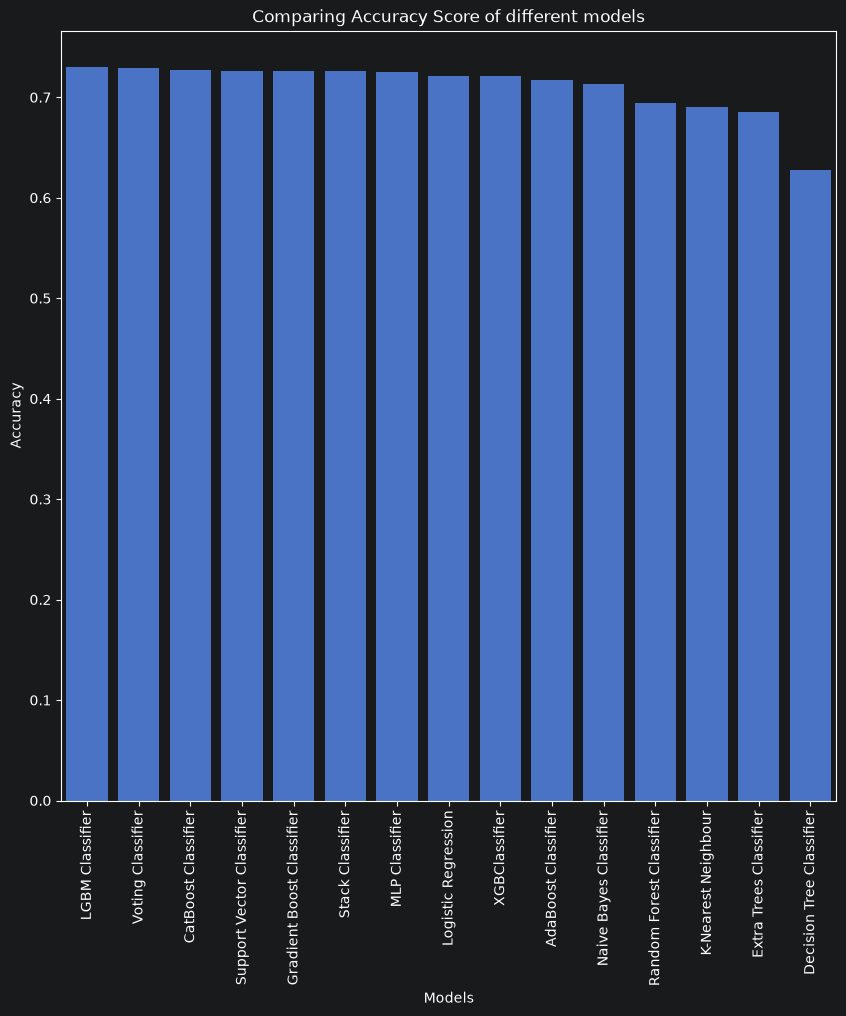

In [61]:
fig, ax=plt.subplots(figsize=(10,10))
sns.barplot(
    data=comparison_df,
    x='model',
    y='accuracy_score'
)
plt.xticks(rotation=90)
ax.set_title("Comparing Accuracy Score of different models")
ax.set_xlabel("Models")
ax.set_ylabel("Accuracy")
plt.show()

In [62]:
curve_dataframe=pd.DataFrame(
    {
        "True":y_test,
        "LGBM Classifier":lgb.predict_proba(X_test_scaled)[:,1],
        "Stack Classifier":stack.predict_proba(X_test_scaled)[:,1],
        "CatBoost Classifier":catboost.predict_proba(X_test_scaled)[:,1],
        "Gradient Boost Classifier":gradient_boost.predict_proba(X_test_scaled)[:,1],
        "Random Forest Classifier":random_forest.predict_proba(X_test_scaled)[:,1],
        "Extra Trees Classifier":extra_trees_classifier.predict_proba(X_test_scaled)[:,1],
        "Voting Classifier":vc.predict_proba(X_test_scaled)[:,1],
        "XGB Classifier":xgb.predict_proba(X_test_scaled)[:,1],
        "KNN Classifier":knn.predict_proba(X_test_scaled)[:,1],
        "MLP Classifier":mlp.predict_proba(X_test_scaled)[:,1],
        "Logistic Regression":logistic_regression.predict_proba(X_test_scaled)[:,1],
        "Support Vector Classifier":svc.predict_proba(X_test_scaled)[:,1],
        "AdaBoost Classifier":adaboost.predict_proba(X_test_scaled)[:,1],
        "Decision Tree Classifier":decision_tree.predict_proba(X_test_scaled)[:,1],
        "Naive Bayes Classifier":gnb.predict_proba(X_test_scaled)[:,1]
    }
)
curve_dataframe

,True,LGBM Classifier,Stack Classifier,CatBoost Classifier,Gradient Boost Classifier,Random Forest Classifier,Extra Trees Classifier,Voting Classifier,XGB Classifier,KNN Classifier,MLP Classifier,Logistic Regression,Support Vector Classifier,AdaBoost Classifier,Decision Tree Classifier,Naive Bayes Classifier
17178,1,0.753799,0.814220,0.800954,0.812017,0.530000,0.440000,0.807651,0.798834,0.6,0.816449,0.895140,0.776364,0.743455,0.0,0.999858
16131,1,0.328919,0.304479,0.287631,0.336720,0.330000,0.390000,0.290574,0.302603,0.2,0.230499,0.288144,0.259500,0.402942,0.0,0.012202
10133,0,0.109366,0.120541,0.084719,0.093876,0.210000,0.100000,0.122804,0.182894,0.2,0.041819,0.098934,0.248021,0.285430,0.0,0.000659
17271,1,0.523824,0.532591,0.530634,0.516128,0.781667,0.551667,0.539236,0.538455,0.8,0.549961,0.559308,0.556344,0.556132,1.0,0.345069
53290,1,0.119426,0.149871,0.139055,0.158970,0.140333,0.070000,0.150921,0.114201,0.0,0.109345,0.156806,0.258646,0.348915,0.0,0.004719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58620,1,0.869841,0.838655,0.871588,0.819895,0.910000,0.930000,0.839399,0.809744,1.0,0.864263,0.756620,0.883846,0.620932,1.0,0.804993
30028,1,0.837916,0.809529,0.812310,0.760223,0.670000,0.810000,0.797299,0.799053,0.8,0.880161,0.746761,0.744669,0.584259,1.0,0.949982
745,1,0.820609,0.816661,0.825819,0.816072,0.918143,0.930000,0.802140,0.872793,1.0,0.820550,0.671873,0.787265,0.604491,1.0,0.875907
29366,1,0.331728,0.301915,0.285505,0.361534,0.420000,0.360000,0.387282,0.316578,0.6,0.416814,0.389530,0.609286,0.448213,0.0,0.270580


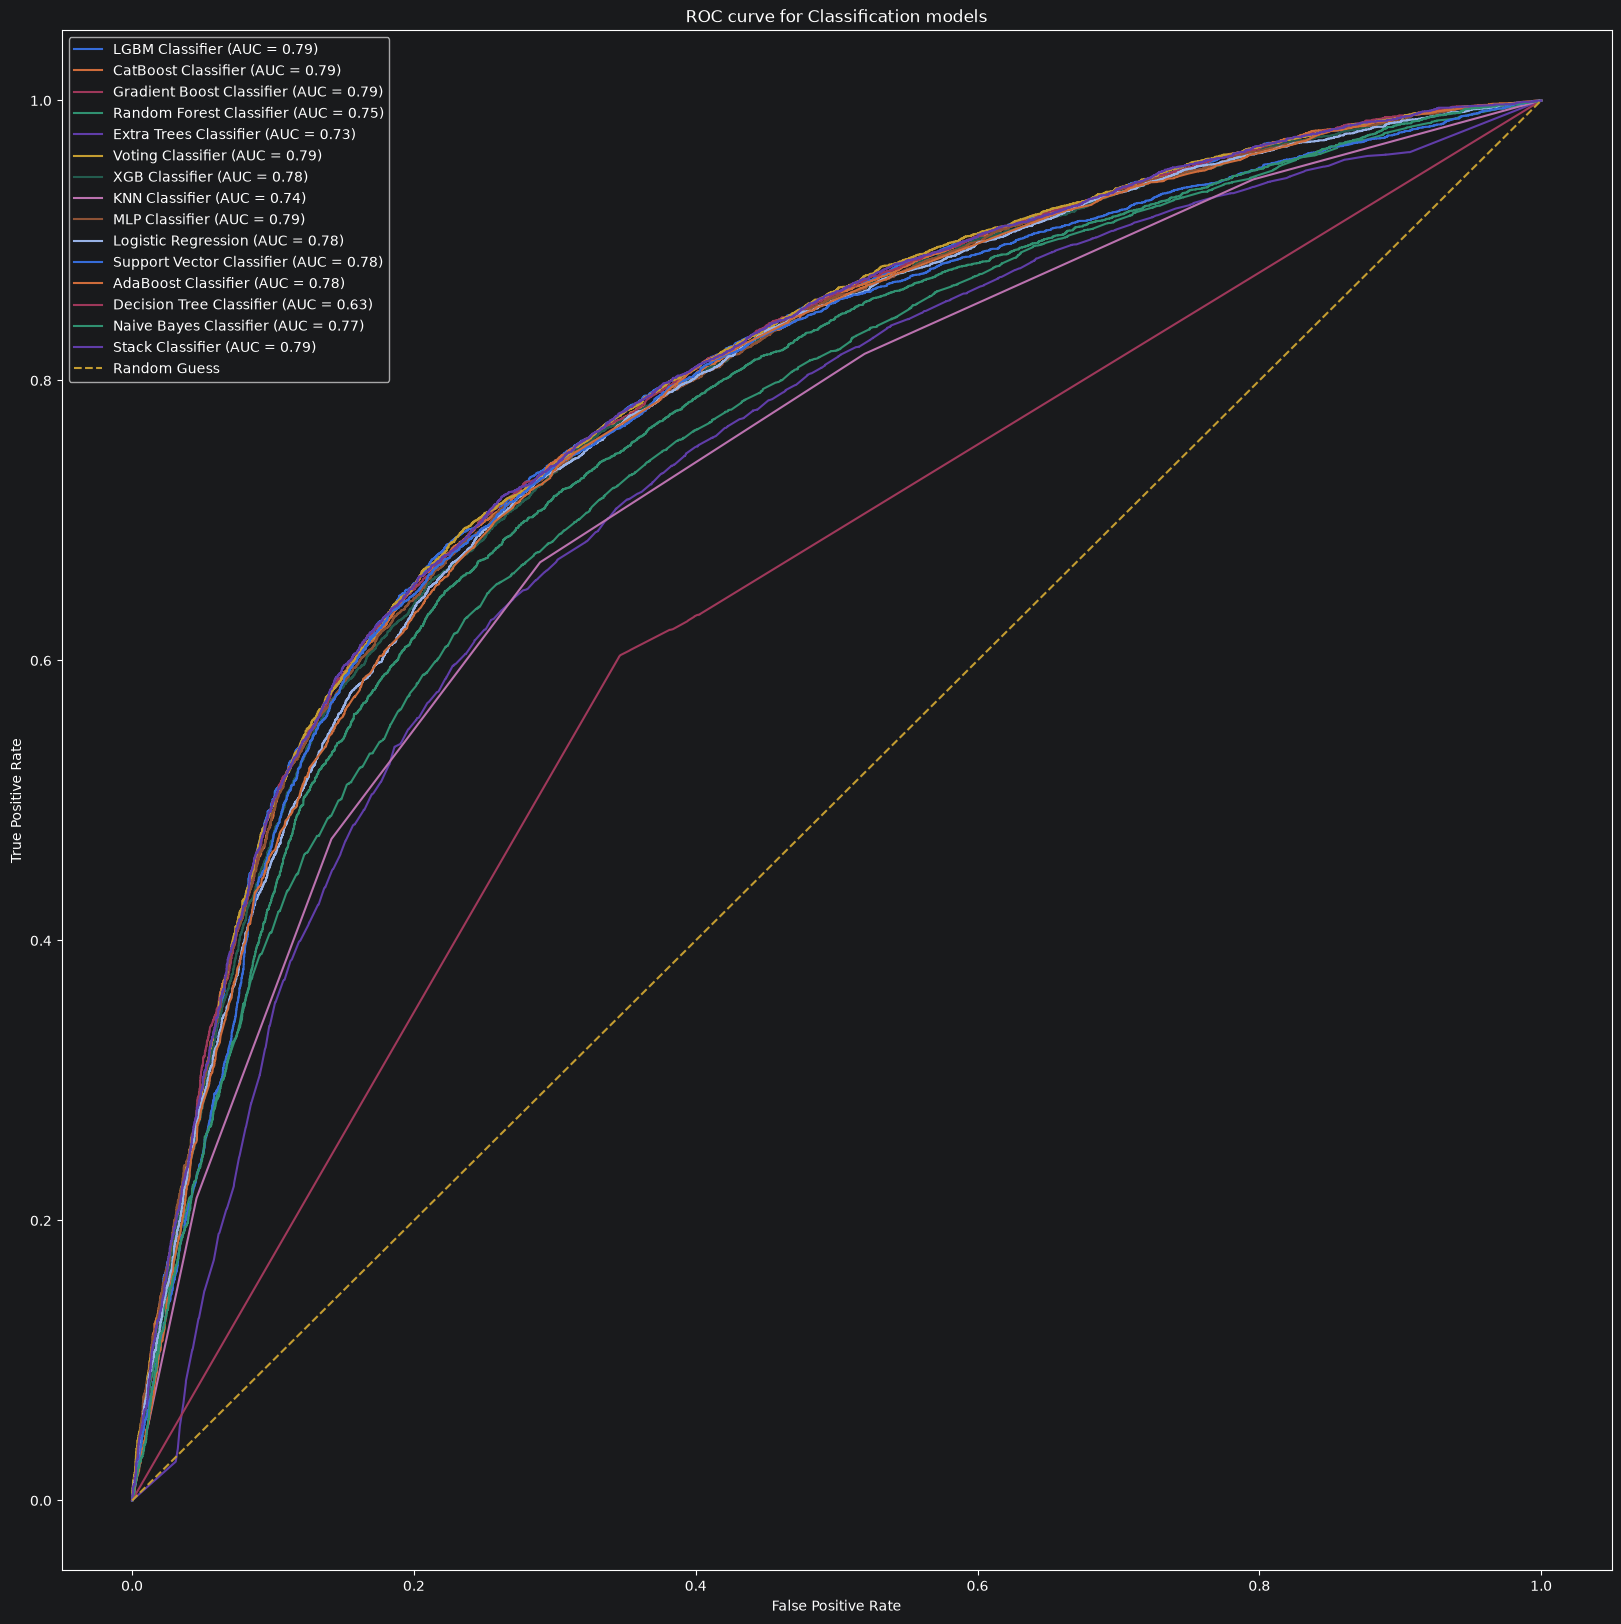

In [63]:
models=['LGBM Classifier', 'CatBoost Classifier','Gradient Boost Classifier','Random Forest Classifier','Extra Trees Classifier','Voting Classifier','XGB Classifier','KNN Classifier','MLP Classifier','Logistic Regression','Support Vector Classifier','AdaBoost Classifier','Decision Tree Classifier','Naive Bayes Classifier', 'Stack Classifier']
fig, ax=plt.subplots(figsize=(20,20))
for i in models:
    fpr, tpr, _ = roc_curve(curve_dataframe['True'],curve_dataframe[i])
    roc_auc=auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        label=f"{i} (AUC = {roc_auc:.2f})"
    )
ax.plot([0,1],[0,1], label="Random Guess", linestyle="--")
ax.set_title("ROC curve for Classification models")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.show()

***LGBM Classifier is the best model.***

## Hyper Parameter Tuning

In [64]:
from sklearn.model_selection import GridSearchCV
lgbm_params={
    'n_estimators':[300,500],
    'learning_rate':[0.03,0.05],
    'max_depth':[5,6],
    'num_leaves':[31,50],
    'min_child_samples':[10,20],
    'subsample':[0.8],
    'colsample_bytree':[0.8],
    'subsample_freq':[1],
    'reg_alpha':[0.0,0.1,1.0],
    'reg_lambda':[0.0,1.0,5.0],
    'min_split_gain':[0.0,0.01]
}
lgbm=LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
grid_search=GridSearchCV(
    estimator=lgbm,
    param_grid=lgbm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled,y_train)
lgbm_best_params=grid_search.best_params_
best_lgbm=grid_search.best_estimator_

In [65]:
lgbm_best_params

{'colsample_bytree': 0.8,
 'learning_rate': 0.05,
 'max_depth': 5,
 'min_child_samples': 10,
 'min_split_gain': 0.01,
 'n_estimators': 300,
 'num_leaves': 50,
 'reg_alpha': 0.0,
 'reg_lambda': 5.0,
 'subsample': 0.8,
 'subsample_freq': 1}

In [66]:
lgbm=best_lgbm
lgbm.fit(X_train_scaled,y_train)
y_pred_lgbm=lgbm.predict(X_test_scaled)
accuracy_lgbm=accuracy_score(y_test, y_pred_lgbm)
recall_lgbm=recall_score(y_test, y_pred_lgbm)
precision_lgbm=precision_score(y_test, y_pred_lgbm)
f1_score_lgbm=f1_score(y_test, y_pred_lgbm)
confusion_matrix_lgbm=confusion_matrix(y_test, y_pred_lgbm)
print(f"Accuracy: {accuracy_lgbm}")
print(f"Recall: {recall_lgbm}")
print(f"Precision: {precision_lgbm}")
print(f"F1 Score: {f1_score_lgbm}")
print("Confusion Matrix")
print(confusion_matrix_lgbm)
print("Classification Report")
print(classification_report(y_test, y_pred_lgbm))

Accuracy: 0.7283548018914071
Recall: 0.6801397205588823
Precision: 0.7437249909057839
F1 Score: 0.7105125977410947
Confusion Matrix
[[4845 1409]
 [1923 4089]]
Classification Report
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      6254
           1       0.74      0.68      0.71      6012

    accuracy                           0.73     12266
   macro avg       0.73      0.73      0.73     12266
weighted avg       0.73      0.73      0.73     12266



## Saving the model

In [67]:
import joblib

joblib.dump(lgbm, '../model/lgbm_model.pkl')

['../model/lgbm_model.pkl']

## Saving the scaler

In [68]:
joblib.dump(standard_scaler, '../model/standard_scaler.pkl')

['../model/standard_scaler.pkl']